# Compare metadata models: deduplicated Subset data

We compare five ways to predict malignancy from age, sex and anatomical site, the metadata recorded alongside each image. The questions are which model ranks malignant images best and which fields add useful information.

[03_patient_fold_verification.ipynb](03_patient_fold_verification.ipynb) supplies shared patient groups, or folds. [04_metadata_baselines.ipynb](04_metadata_baselines.ipynb) introduces the two simplest references. Every method here is assessed on patients excluded from its own training.

The saved run favours spline logistic regression, which learns a smooth age relationship: average precision (AP) 0.0492 pooled (0.0648 mean-fold) versus 0.0184 pooled (0.0189 mean-fold) for the dummy. These are development comparisons, before adding images; the reserved test is not used.

For metric definitions, see the [short concept guide](../concepts.md).


**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [05_metadata_models.ipynb](../Subset/05_metadata_models.ipynb).

The clean workflow's primary ranking measure is **unweighted mean outer-fold AP**. The original pooled tables and figures are retained for presentation consistency and are explicitly secondary; their values are not interchangeable with mean-fold scores.

## Context and methods

We predict the outcome of each image, while keeping related images from one patient together. For each fold, train on the other four and predict the held-out group. Combining the five groups gives out-of-fold (OOF) predictions: each scored patient was excluded from their model's training.

Preprocessing, converting raw fields into model inputs, is fitted inside training. Validation patients cannot change categories, missing-age replacements or the learned age curve. Exclude diagnosis and benign/malignant descriptions because they reveal the answer, plus identifiers and fold numbers.

Only 1.89% of images are malignant. Average precision (AP), the main measure, rewards placing these rare cases near the top of a score ranking. The results also explain ROC-AUC and probability-error measures. An output in [0,1] is a probability estimate, not proof that its numerical risk is accurate.

Confusion-matrix cutoffs are chosen and assessed from the same OOF labels, so they illustrate exploratory trade-offs. [08_metadata_robustness.ipynb](08_metadata_robustness.ipynb) separates cutoff selection from assessment.


### What each model contributes

| Model | Why include it? | What it learns |
|---|---|---|
| Prevalence dummy | Set a reference for a model with no useful ranking | The malignant-image rate in its training data |
| Standard logistic regression | Start with a simple, readable model | Separate effects for each age category, sex and site |
| Spline logistic regression | Let nearby ages share a smooth pattern | A smooth age curve, plus sex and site effects |
| Random forest | Check whether combinations of fields help | Many decision trees whose predictions are averaged |
| XGBoost | Check a second way to combine decision trees | Trees fitted in sequence to improve earlier predictions |

The spline model uses four knots, which are points where its age curve can bend. This gives age some flexibility without fitting a separate effect to every age category. These settings were chosen as a starting specification; this notebook does not search for the best settings.


## Data

### Set paths and define the modelling tools

The following cells define the models and how we check them. All five methods read the same development data and use the same patient folds, so differences in results reflect the model choices.


In [1]:
NOTEBOOK_STAGE = '05_metadata_models'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcdefaults()
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
FIGURE_DIR = ROOT / DIRECTORY / "figures" / "template_v3" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename, *, dpi=None):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=dpi or globals().get("ORIGINAL_EXPORT_DPI", 150), bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


from pathlib import Path
import json
import joblib
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.metrics import (
    PrecisionRecallDisplay, RocCurveDisplay, average_precision_score,
    balanced_accuracy_score, brier_score_loss, confusion_matrix, log_loss,
    roc_auc_score, roc_curve, precision_recall_curve,
)
from melanoma_detection.metadata_evaluation import probability_metrics, decision_metrics, calibration_bins
from melanoma_detection.dedup_notebook_metadata import (
    saved_metadata, metric_table, exploratory_cutoff, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
from melanoma_detection.dedup_notebook_metadata_templates import marginal_age_profile, metadata_patient_intervals
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
PROJECT_ROOT = ROOT
train = bundle["frame"].set_index("image_name").loc[frame.image_id].reset_index()
assert np.array_equal(train.patient_id, frame.patient_id)
assert np.array_equal(train.target, frame.target)
assert np.array_equal(train.fold, frame.fold)
assert train.groupby("patient_id").fold.nunique().eq(1).all()
assert train.image_name.is_unique and len(train) == 6706
assert int(train.target.sum()) == 127
FEATURE_COLUMNS = ["sex", "age_approx", "anatom_site_general_challenge"]
FEATURES = FEATURE_COLUMNS
DATA_PATH = ROOT / "data/subset/processed/dedup_v1/dataset_manifest.json"
TRAIN_FOLDS_PATH = DATA_PATH
REPORT_DIR = ROOT / "results/dedup_v1/clean_workflow/metadata_depth" / NOTEBOOK_STAGE
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES = FIGURE_DIR
TABLES = METRICS = PREDICTIONS = REPORT_DIR
plt.rcdefaults()

def binary_probability_metrics(targets, probabilities):
    values = probability_metrics(targets, probabilities)
    return {"roc_auc": values["roc_auc"], "average_precision": values["average_precision"],
            "log_loss": values["log_loss"], "brier_score": values["brier"]}

MODEL_LABELS = {"dummy": "Prevalence dummy", "logistic": "Standard logistic regression",
    "spline_logistic": "Spline logistic regression", "random_forest": "Random forest", "xgboost": "XGBoost"}
ALIASES = {"dummy": "dummy", "logistic": "categorical_logistic", "spline_logistic": "spline_raw",
    "random_forest": "random_forest", "xgboost": "xgboost"}
CURVES_PATH = FIGURE_DIR / "metadata_baseline_curves_dedup_v1.png"
set_matplotlib_formats("retina")
plt.rcParams["figure.dpi"] = 120

ORIGINAL_EXPORT_DPI = 320


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

### Define the shared preprocessing

The standard models turn each category into a yes/no column, a process called one-hot encoding. For example, a site column records whether an image comes from the torso. Age is also treated as a category for these comparisons.

The spline model treats age as a number and learns a smooth curve. It fills a missing age with the training median and scales the curve's numerical features. Each training fold learns its own transformation, using only its training patients.


In [2]:

display(pd.DataFrame([{"Model": "Categorical models", "Age": "one-hot age categories", "Other fields": "training-learned one-hot sex/site"},
    {"Model": "Spline logistic", "Age": "training median; four quantile knots; cubic spline; training scale", "Other fields": "training-learned one-hot sex/site"}]))
display(pd.DataFrame([meta["core"]["specification"]["spline"]]).T)


,Model,Age,Other fields
0,Categorical models,one-hot age categories,training-learned one-hot sex/site
1,Spline logistic,training median; four quantile knots; cubic sp...,training-learned one-hot sex/site


,0
model,fixed_spline_logistic
features,"[age_approx, sex, anatom_site_general_challenge]"
age_knots,4
age_degree,3
age_knot_placement,quantile
logistic_C,1.0
class_weight,None
seed,42
primary_probability,raw
threshold_rule,highest cutoff attaining training OOF recall


### Define how we generate held-out predictions

The separate clean runner created a fresh copy of each model for every fold, fit it on four folds and predict the fifth. This report reads verified saved predictions and aligns them with retained image identities; it does not refit models. The next cell checks that no patient appears in more than one fold.


In [3]:

assert train.groupby("patient_id").fold.nunique().eq(1).all()
display(train.groupby("fold").agg(images=("target", "size"), malignant_images=("target", "sum"), patients=("patient_id", "nunique")))
print("Saved receipt verified; no fresh model fitting is performed by this notebook.")


,images,malignant_images,patients
fold,,,
0,1344,24,84
1,1366,26,84
2,1328,26,87
3,1371,25,82
4,1297,26,85


Saved receipt verified; no fresh model fitting is performed by this notebook.


### Load and check the development data

Before reading the saved fits, check that the required fields are present, the target contains both classes and every patient stays in one fold. The counts below describe the data used for every comparison.


In [4]:

print(f"Manifest: {DATA_PATH.relative_to(ROOT)}")
print(f"Dataset identity: {bundle['identity']['dataset_identity']}")
print(f"Images: {len(train):,}; patients: {train.patient_id.nunique():,}")
print(f"Malignant images: {int(train.target.sum()):,} ({train.target.mean():.2%})")
print(f"Malignant patients: {train.loc[train.target.eq(1), 'patient_id'].nunique():,}")
print("Original patient folds retained; reserved test not loaded.")


Manifest: data\subset\processed\dedup_v1\dataset_manifest.json
Dataset identity: 0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae9f9eb7e57825b04af1
Images: 6,706; patients: 422
Malignant images: 127 (1.89%)
Malignant patients: 88
Original patient folds retained; reserved test not loaded.


## Results

### 1. Load patient-safe out-of-fold predictions

In the completed clean run, each model trained on the other four folds and predicted the held-out fold. Repeating this process gives one validation probability for every image while keeping patients separated.


In [5]:

estimators = dict(ALIASES)
oof_predictions = train[["image_name", "patient_id", "fold", "target"]].copy()
for model_name, score_name in ALIASES.items():
    oof_predictions[f"{model_name}_probability"] = scores[score_name]
assert oof_predictions.filter(like="probability").notna().all().all()
print(f"Loaded {len(oof_predictions):,} matched clean OOF predictions for five models.")


Loaded 6,706 matched clean OOF predictions for five models.


### 2. Compare probability performance

The table compares all five models on their combined held-out predictions. AP and ROC-AUC are better when larger; log loss and Brier score are better when smaller. Use the added mean-fold AP table first; pooled metrics retain the original descriptive view. Use AP first, then check whether the other measures tell a consistent story.


In [6]:
metric_records = []
for model_name in estimators:
    probability_column = f"{model_name}_probability"
    overall = binary_probability_metrics(
        oof_predictions["target"],
        oof_predictions[probability_column],
    )
    metric_records.append(
        {"scope": "overall_oof", "fold": pd.NA, "model": model_name, **overall}
    )

    for fold in sorted(oof_predictions["fold"].unique()):
        fold_mask = oof_predictions["fold"].eq(fold)
        fold_metrics = binary_probability_metrics(
            oof_predictions.loc[fold_mask, "target"],
            oof_predictions.loc[fold_mask, probability_column],
        )
        metric_records.append(
            {"scope": "fold", "fold": int(fold), "model": model_name, **fold_metrics}
        )

metrics = pd.DataFrame(metric_records)
overall_metrics = (
    metrics.query("scope == 'overall_oof'")
    .drop(columns=["scope", "fold"])
    .set_index("model")
    .rename(index=MODEL_LABELS)
)
overall_metrics.round(4)
display(overall_metrics.round(4))
primary_metrics = metric_table(frame, scores, list(ALIASES.values())).query("scope == 'mean_fold'")
display(primary_metrics.set_index("model")[["average_precision", "roc_auc", "log_loss", "brier"]].round(5))


,roc_auc,average_precision,log_loss,brier_score
model,,,,
Prevalence dummy,0.4877,0.0184,0.0939,0.0186
Standard logistic regression,0.5943,0.0430,0.0924,0.0185
Spline logistic regression,0.6428,0.0492,0.0909,0.0184
Random forest,0.6033,0.0433,0.0919,0.0184
XGBoost,0.5893,0.0434,0.0938,0.0185


,average_precision,roc_auc,log_loss,brier
model,,,,
dummy,0.01895,0.50000,0.09393,0.01859
categorical_logistic,0.05669,0.59695,0.09244,0.01849
spline_raw,0.06484,0.65563,0.09101,0.01842
random_forest,0.05477,0.60319,0.09195,0.01845
xgboost,0.05907,0.59304,0.09385,0.01851


### How to read the scores

- Average precision (AP) rewards placing malignant images near the top of the risk ranking. It is not the percentage of images classified correctly. The dummy's 0.0184 provides a reference close to the malignant-image rate.
- ROC-AUC describes how often a malignant image gets a higher score than a benign image. A value of 0.5 is chance-level ranking; 1 is perfect ranking.
- Log loss penalises incorrect probability estimates, especially confident mistakes. Smaller is better.
- Brier score is the average squared difference between the probability and the actual 0/1 label. Smaller is better. With many benign images, a small Brier score alone can hide poor detection of malignant cases.

The spline leads on pooled and mean-fold AP and on pooled ROC-AUC among these fixed models. Its primary mean-fold AP is 0.0648. Its AP of 0.0492 is still low, so its higher score does not make metadata a reliable standalone diagnostic method.


### 3. Check how results vary across patient folds

Each row below is a different held-out patient group. Compare the same model across rows before judging its pooled score. Large changes suggest that the result depends on which patients happen to be held out.


In [7]:
fold_model_metrics = (
    metrics.query("scope == 'fold' and model != 'dummy'")
    .pivot(index="fold", columns="model", values=["roc_auc", "average_precision"])
    .rename(columns=MODEL_LABELS, level=1)
)
fold_model_metrics.round(4)
display(fold_model_metrics.round(4))


roc_auc                                           \
model Standard logistic regression Random forest Spline logistic regression   
fold                                                                          
0                           0.6443        0.6487                     0.7944   
1                           0.5042        0.5025                     0.5588   
2                           0.5513        0.5802                     0.6311   
3                           0.7051        0.6661                     0.6840   
4                           0.5798        0.6186                     0.6098   

                         average_precision                \
model XGBoost Standard logistic regression Random forest   
fold                                                       
0      0.6423                       0.0442        0.0415   
1      0.5236                       0.0488        0.0559   
2      0.5001                       0.0327        0.0324   
3      0.7243                       0.0663        0.0609   
4      0.5749                       0.0915        0.0832   

                                          
model Spline logistic regression XGBoost  
fold                                      
0                         0.0662  0.0522  
1                         0.0460  0.0623  
2                         0.0373  0.0264  
3                         0.0624  0.0690  
4                         0.1122  0.0855

The spline's AP ranges from 0.0373 to 0.1122 across folds. Different patient groups produce different results, and the spline does not lead every fold. This variation is a reason to check uncertainty in later model comparisons.


### 4. Read the ROC and precision-recall curves

Each row is one model: blue logistic regression, gold spline, olive random forest and orange XGBoost. Curves trace changing cutoffs; axis fractions such as 0.2 mean 20%.

- **Left: ROC.** The horizontal axis is benign images incorrectly flagged (false-positive rate); the vertical axis is malignant images found (recall). Closer to the upper-left is better. The grey diagonal is chance ranking.
- **Right: precision-recall.** Recall is horizontal; precision, the malignant share of flagged images, is vertical. Higher precision at the same recall means fewer false alarms. The grey line marks the 1.89% malignant-image share. The vertical view stops at 30%, excluding the endpoint at recall zero and precision one.

Read both panels: above-chance ranking can coexist with low precision. These curves compare cutoffs without endorsing one.


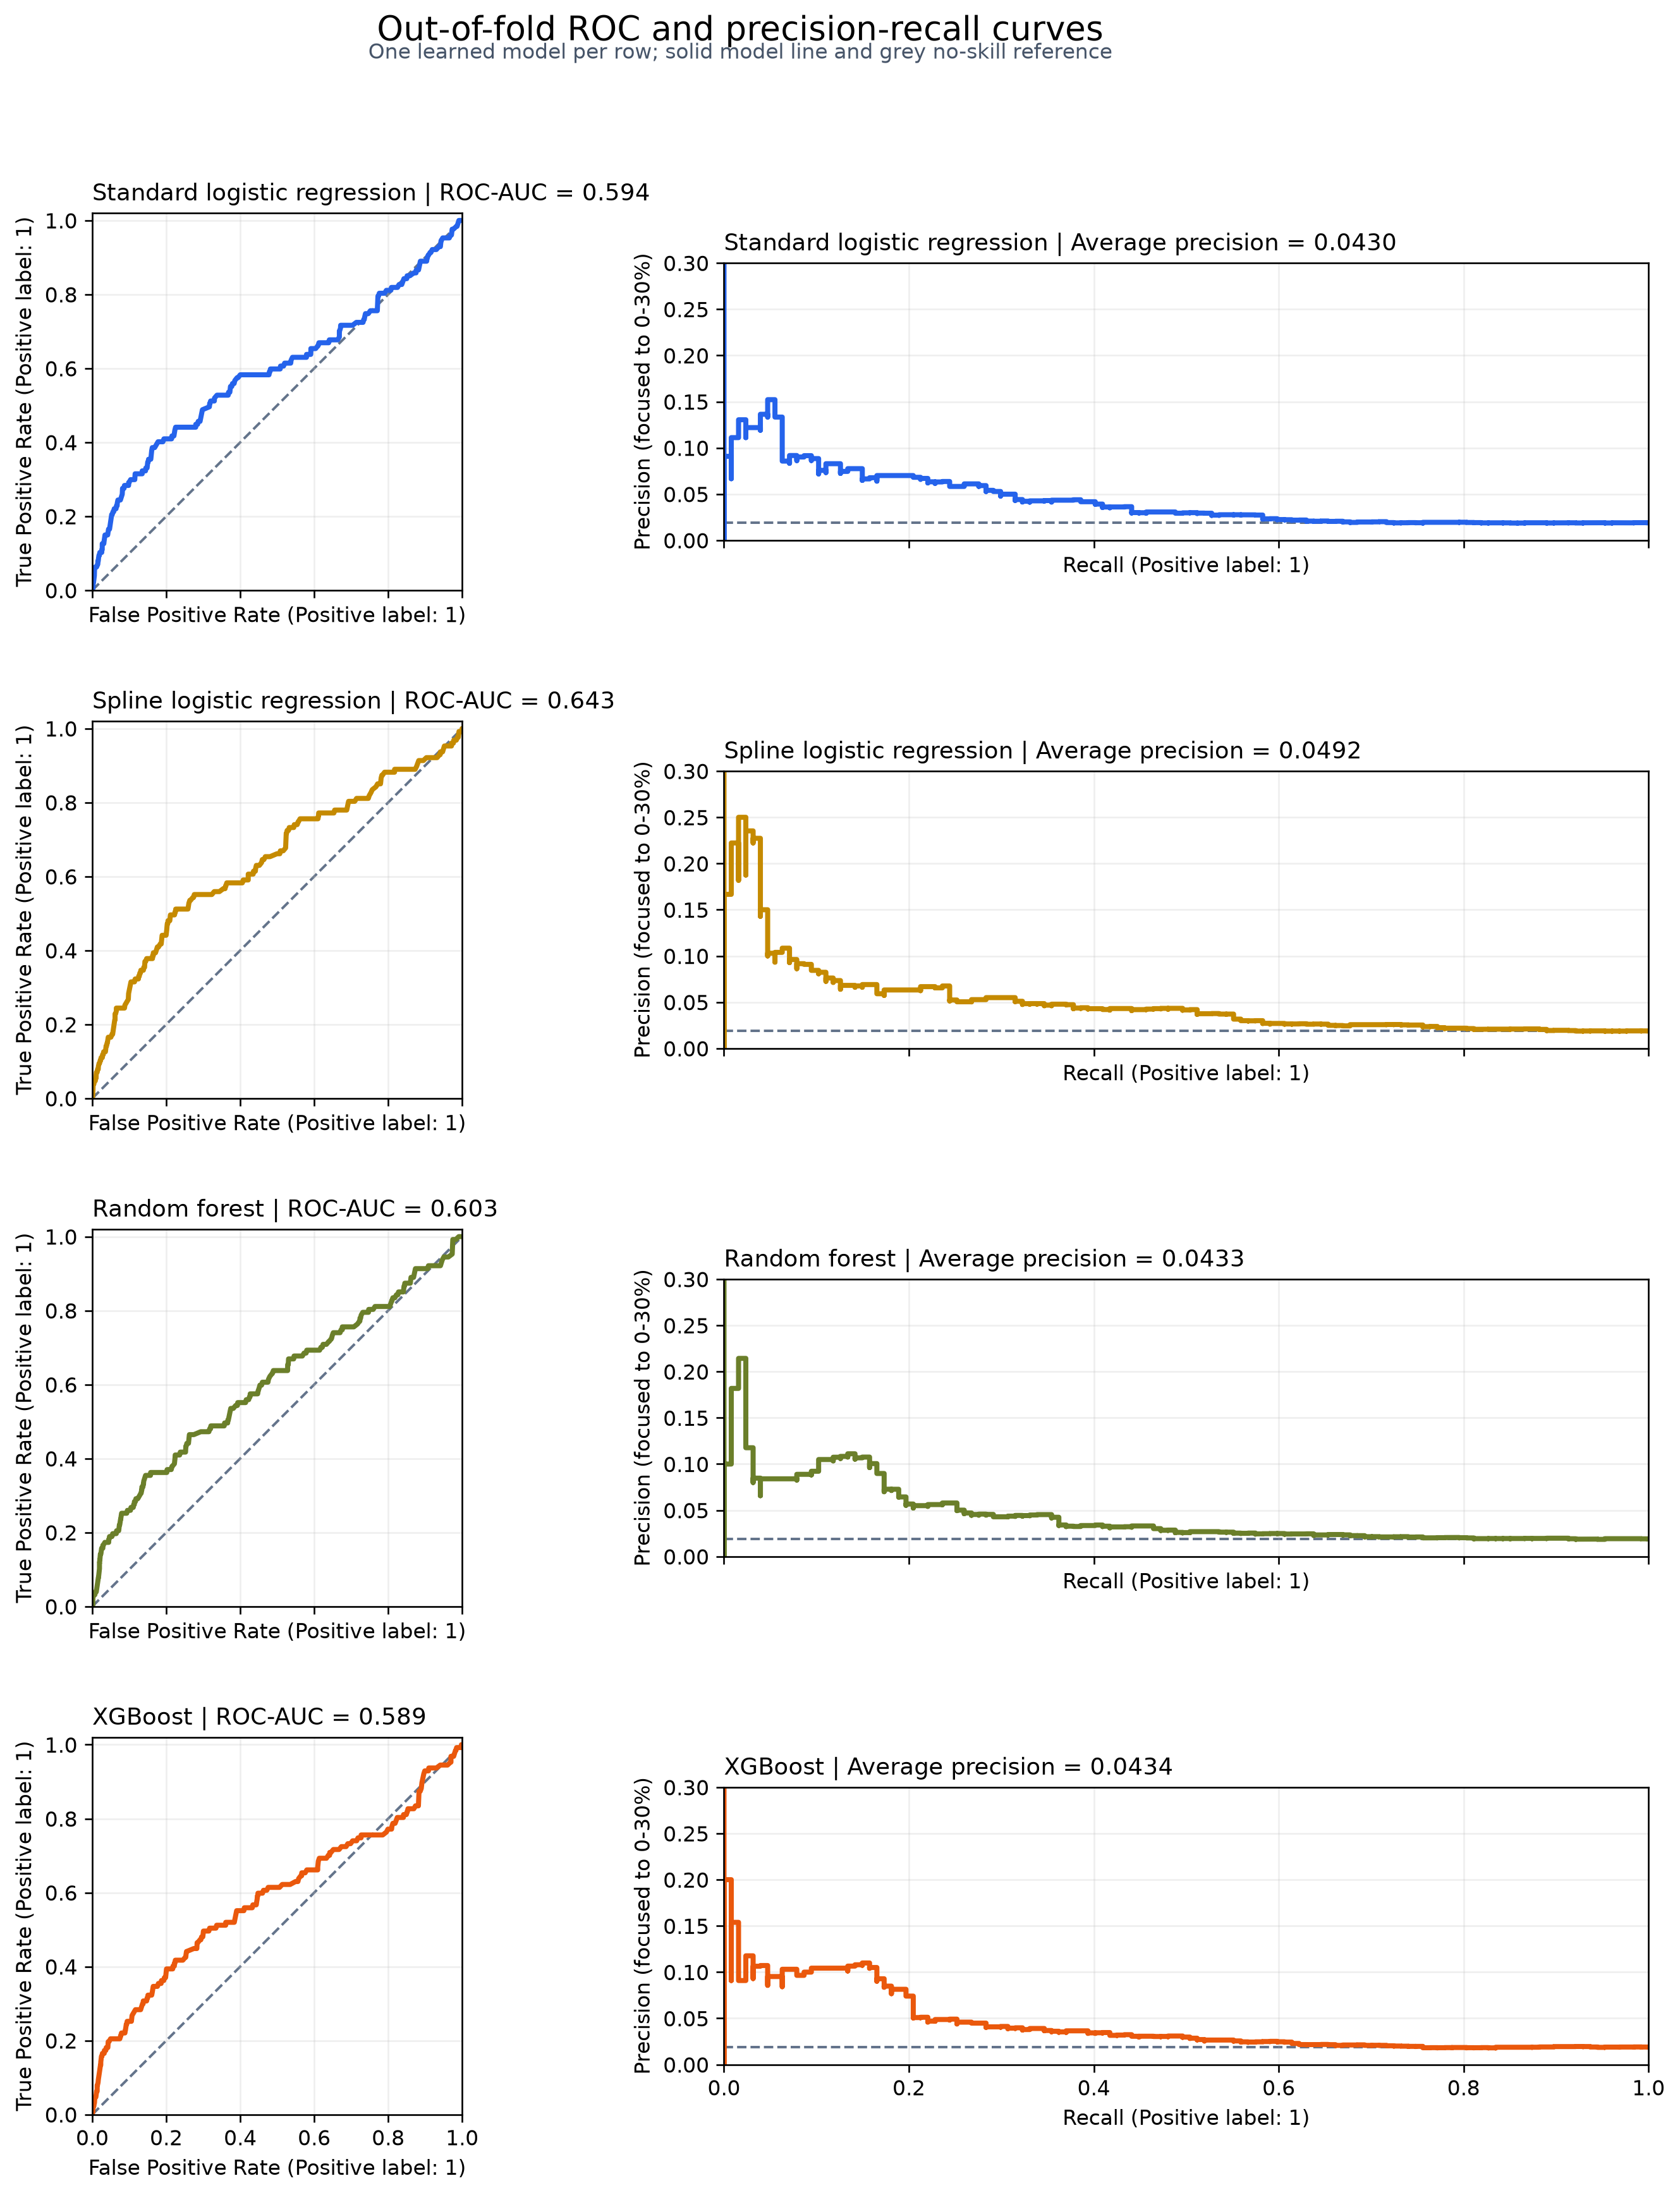

In [8]:
COLORS = {
    "logistic": "#2563EB",
    "spline_logistic": "#C58A00",
    "random_forest": "#6B7F2A",
    "xgboost": "#EA580C",
}

learned_model_names = [
    "logistic",
    "spline_logistic",
    "random_forest",
    "xgboost",
]
fig, axes = plt.subplots(
    len(learned_model_names),
    2,
    figsize=(12.5, 14.5),
    sharex="col",
    sharey="col",
)

for row, model_name in enumerate(learned_model_names):
    probability_column = f"{model_name}_probability"
    model_label = MODEL_LABELS[model_name]
    model_color = COLORS[model_name]
    roc_axis, precision_recall_axis = axes[row]

    RocCurveDisplay.from_predictions(
        oof_predictions["target"],
        oof_predictions[probability_column],
        name=model_label,
        curve_kwargs={
            "color": model_color,
            "linestyle": "-",
            "linewidth": 2.4,
        },
        ax=roc_axis,
    )
    roc_axis.plot(
        [0, 1],
        [0, 1],
        color="#64748B",
        linestyle="--",
        linewidth=1.2,
        zorder=0,
    )
    roc_axis.set_title(
        f"{model_label} | ROC-AUC = "
        f"{overall_metrics.loc[model_label, 'roc_auc']:.3f}",
        loc="left",
        fontsize=11,
    )
    roc_axis.set_xlim(0, 1)
    roc_axis.set_ylim(0, 1.02)

    PrecisionRecallDisplay.from_predictions(
        oof_predictions["target"],
        oof_predictions[probability_column],
        name=model_label,
        curve_kwargs={
            "color": model_color,
            "linestyle": "-",
            "linewidth": 2.4,
        },
        ax=precision_recall_axis,
    )
    precision_recall_axis.axhline(
        train["target"].mean(),
        color="#64748B",
        linestyle="--",
        linewidth=1.2,
        zorder=0,
    )
    precision_recall_axis.set_title(
        f"{model_label} | Average precision = "
        f"{overall_metrics.loc[model_label, 'average_precision']:.4f}",
        loc="left",
        fontsize=11,
    )
    precision_recall_axis.set_xlim(0, 1)
    precision_recall_axis.set_ylim(0, 0.30)
    precision_recall_axis.set_ylabel("Precision (focused to 0-30%)")

    for axis in (roc_axis, precision_recall_axis):
        legend = axis.get_legend()
        if legend is not None:
            legend.remove()
        axis.grid(alpha=0.20)

fig.suptitle(
    "Out-of-fold ROC and precision-recall curves",
    fontsize=16,
    y=0.995,
)
fig.text(
    0.5,
    0.975,
    "One learned model per row; solid model line and grey no-skill reference",
    ha="center",
    fontsize=10,
    color="#475569",
)
fig.tight_layout(rect=[0, 0, 1, 0.955], h_pad=3.0, w_pad=2.0)

CURVES_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(CURVES_PATH, dpi=320, bbox_inches="tight")
finish_figure(fig, 'metadata_five_model_curves')


### 5. Remove fields to see where the signal comes from

The separate clean runner refitted the same spline-logistic model using different combinations of age, sex and site. This is called feature ablation. Keeping the model and patient folds fixed helps us see what each field adds.

In the chart, the vertical axis lists the field combinations and the horizontal axis is held-out AP. Longer blue bars mean better ranking of malignant images. The dashed vertical line is the dummy reference; the printed values give the exact scores. Compare age alone with age plus site, then compare that with all three fields. There are no uncertainty bars here, so tiny differences should not be read as established gains.


,Features,roc_auc,average_precision,log_loss,brier_score,Average precision gain vs dummy
Feature set,,,,,,
Sex only,sex,0.5191,0.0197,0.0938,0.0186,0.0013
Age only,age_approx,0.6287,0.0412,0.0915,0.0184,0.0229
Site only,anatom_site_general_challenge,0.5478,0.0271,0.0927,0.0185,0.0087
Sex + age,"sex, age_approx",0.6137,0.0403,0.0918,0.0184,0.0220
Sex + site,"sex, anatom_site_general_challenge",0.5776,0.0303,0.0926,0.0185,0.0119
Age + site,"age_approx, anatom_site_general_challenge",0.6530,0.0487,0.0907,0.0184,0.0303
All features,"sex, age_approx, anatom_site_general_challenge",0.6428,0.0492,0.0909,0.0184,0.0308


,scope,fold,average_precision,roc_auc,log_loss,brier
model,,,,,,
ablation_sex,mean_fold,NaN,0.02191,0.55190,0.09382,0.01859
ablation_age,mean_fold,NaN,0.04577,0.65507,0.09156,0.01845
ablation_site,mean_fold,NaN,0.02905,0.56252,0.09272,0.01853
ablation_sex_age,mean_fold,NaN,0.04564,0.63125,0.09189,0.01846
ablation_sex_site,mean_fold,NaN,0.03366,0.58643,0.09261,0.01852
ablation_age_site,mean_fold,NaN,0.06362,0.66653,0.09072,0.01842
ablation_all_features,mean_fold,NaN,0.06484,0.65563,0.09101,0.01842


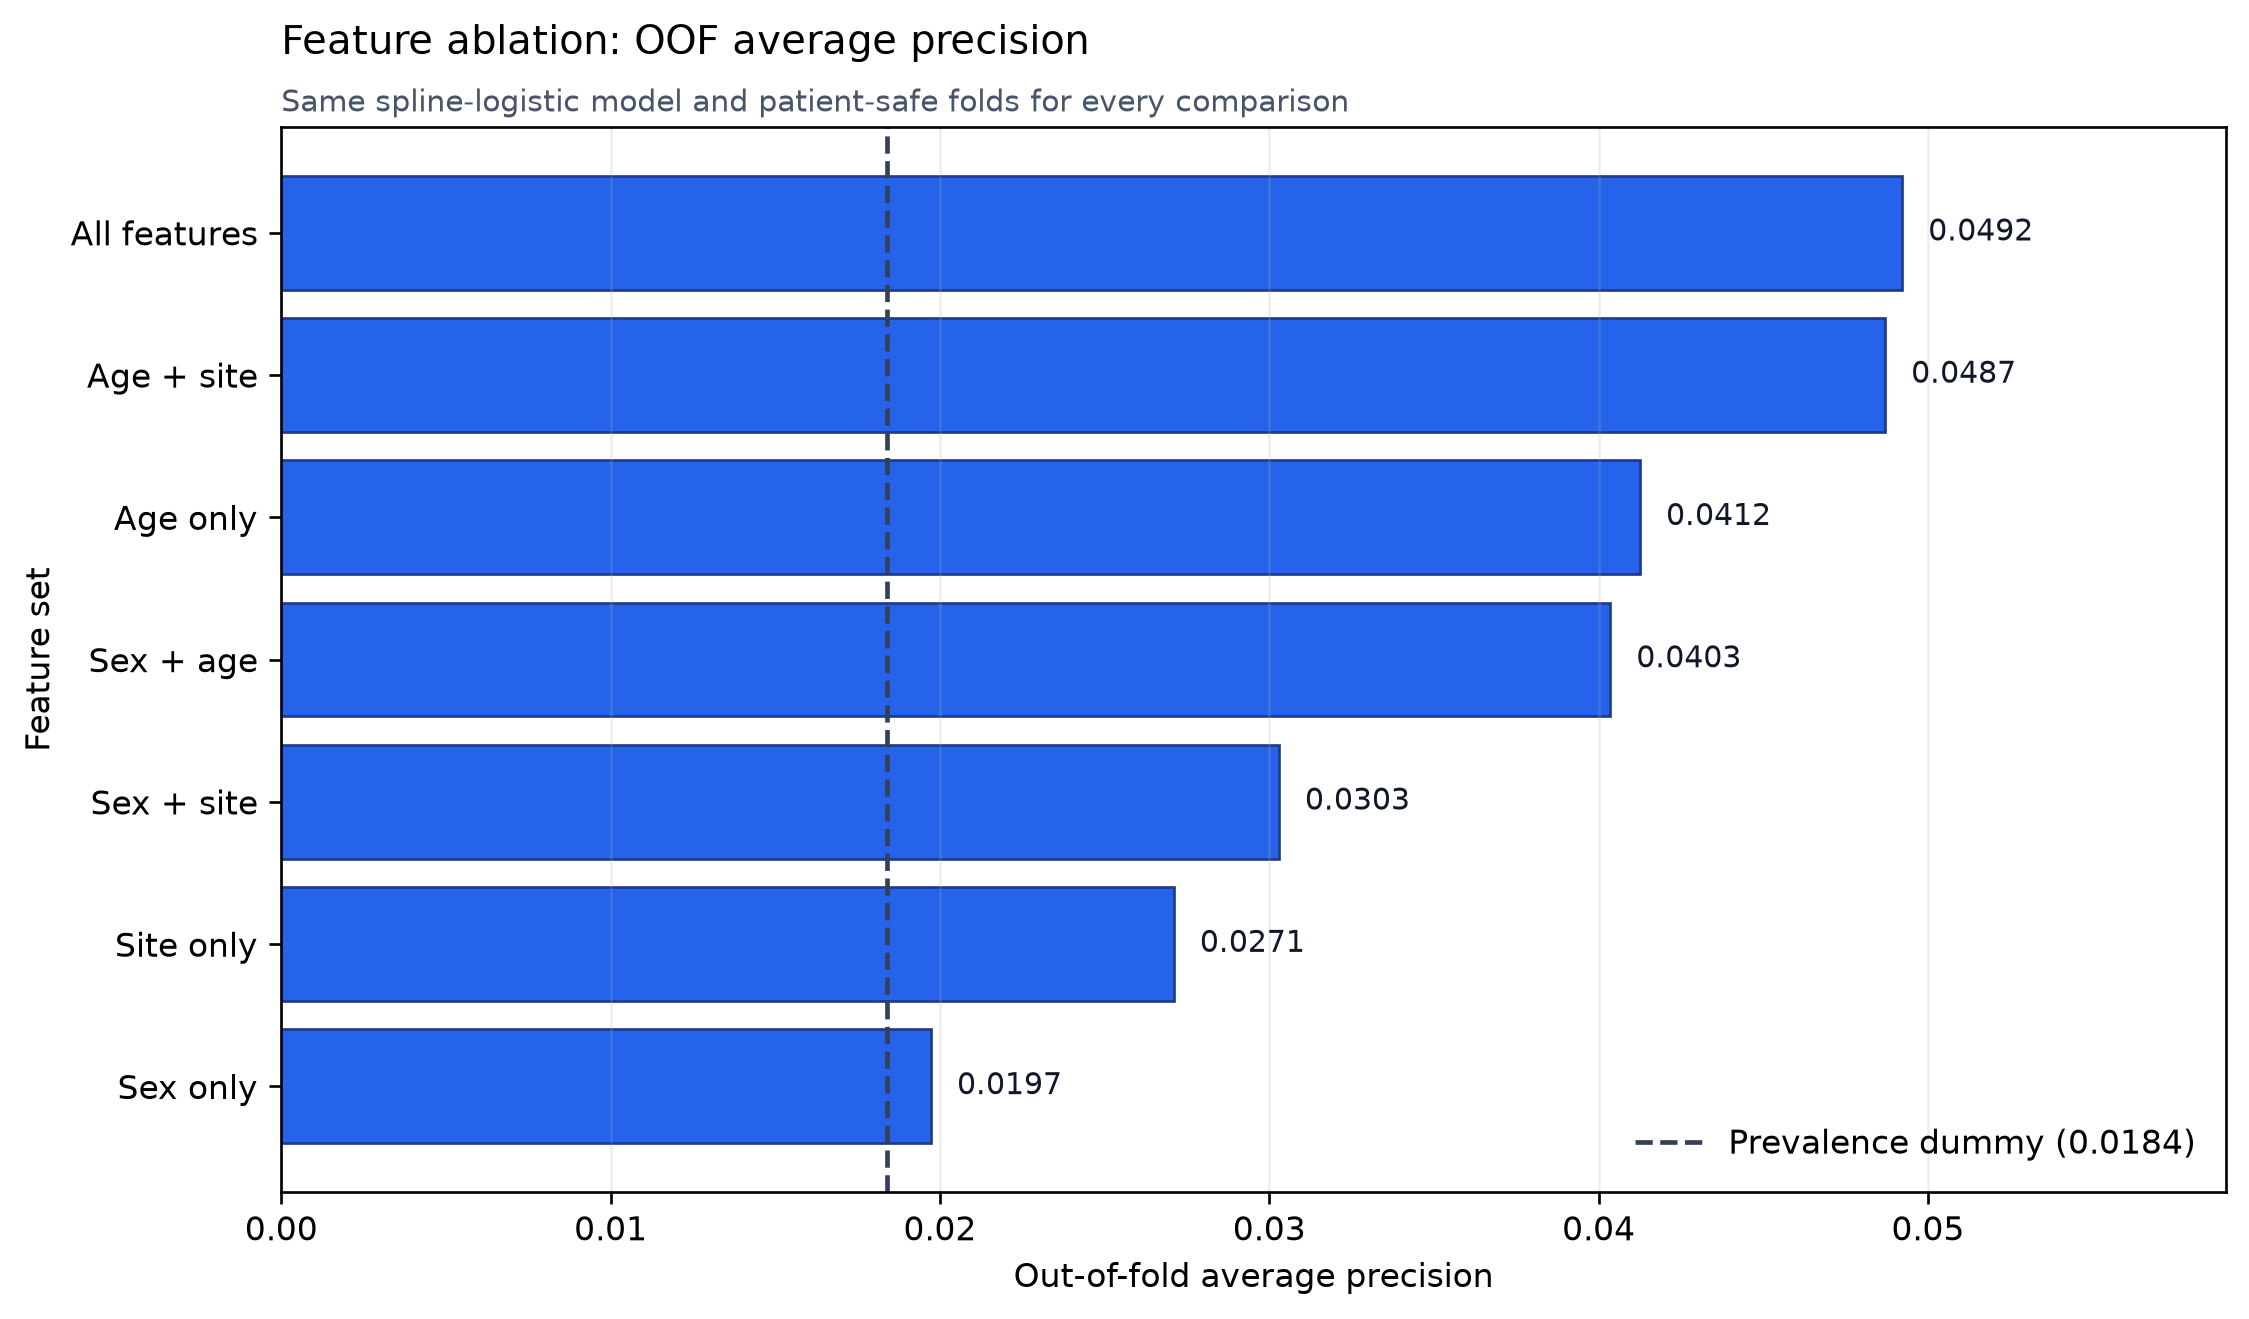

In [9]:

ablation_feature_sets = {"Sex only": ["sex"], "Age only": ["age_approx"], "Site only": ["anatom_site_general_challenge"],
    "Sex + age": ["sex", "age_approx"], "Sex + site": ["sex", "anatom_site_general_challenge"],
    "Age + site": ["age_approx", "anatom_site_general_challenge"], "All features": FEATURE_COLUMNS}
ablation_keys = ["ablation_sex", "ablation_age", "ablation_site", "ablation_sex_age", "ablation_sex_site", "ablation_age_site", "ablation_all_features"]
ablation_rows = [{"Feature set": label, "Features": ", ".join(ablation_feature_sets[label]),
    **binary_probability_metrics(train.target, scores[key])}
    for label, key in zip(ablation_feature_sets, ablation_keys)]
assert np.allclose(scores["ablation_all_features"], scores["spline_raw"], rtol=0, atol=1e-14)
ablation_results = pd.DataFrame(ablation_rows).set_index("Feature set")
dummy_average_precision = overall_metrics.loc["Prevalence dummy", "average_precision"]
ablation_results["Average precision gain vs dummy"] = ablation_results.average_precision - dummy_average_precision
display(ablation_results.round(4))
display(metric_table(frame, scores, ablation_keys).query("scope == 'mean_fold'").set_index("model").round(5))
plot_data =  ablation_results.sort_values("average_precision")
fig, axis = plt.subplots(figsize=(9.5, 5.6))
bars = axis.barh(
    plot_data.index,
    plot_data["average_precision"],
    color="#2563EB",
    edgecolor="#1E3A8A",
    linewidth=0.8,
)
axis.axvline(
    dummy_average_precision,
    color="#334155",
    linestyle="--",
    linewidth=1.4,
    label=f"Prevalence dummy ({dummy_average_precision:.4f})",
)

for bar, value in zip(bars, plot_data["average_precision"]):
    axis.text(
        value + 0.0008,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center",
        fontsize=9,
        color="#0F172A",
    )

axis.set_xlim(0, plot_data["average_precision"].max() * 1.20)
axis.set_xlabel("Out-of-fold average precision")
axis.set_ylabel("Feature set")
axis.set_title("Feature ablation: OOF average precision", loc="left", pad=22)
axis.text(
    0,
    1.015,
    "Same spline-logistic model and patient-safe folds for every comparison",
    transform=axis.transAxes,
    fontsize=9,
    color="#475569",
)
axis.legend(frameon=False, loc="lower right")
axis.grid(axis="x", alpha=0.20)
fig.tight_layout()
finish_figure(fig, 'metadata_seven_feature_ablations')

Age gives the strongest individual signal, with AP 0.0412. Site alone reaches 0.0271, and adding it to age raises AP to 0.0487. Sex alone is close to the dummy, at 0.0197. Adding sex to age and site raises AP slightly to 0.0492 while lowering ROC-AUC from 0.653 to 0.643.

These are pooled AP values, matching the original chart. Primary mean-fold AP is 0.0458 for age, 0.0636 for age plus site and 0.0648 for all three fields. Age and site account for most of the useful signal in this run. The small change from adding sex needs an uncertainty check before we treat it as a dependable improvement. These comparisons describe predictive usefulness, not the causes of melanoma.


### 6. Read the fitted age relationship

**Experiment-scope adaptation:** the original fitted a new all-development spline for this descriptive view. The clean report instead averages predictions from the five saved outer-training spline fits, so no additional model is fitted. For each age, assign that age to all records and average each saved model's scores over the clean records' sex and site, then take the equal mean across saved models. The observed-rate points use the retained development images. The performance scores above still use held-out predictions.

The horizontal axis is approximate age; the vertical axis is percentage. The gold line is this mean marginal model score; blue-outlined points are observed malignant percentages. Larger points mean more images. Compare the broad pattern: small groups can fluctuate sharply. Neither series has uncertainty intervals, and the fitted line does not establish calibrated individual risks.


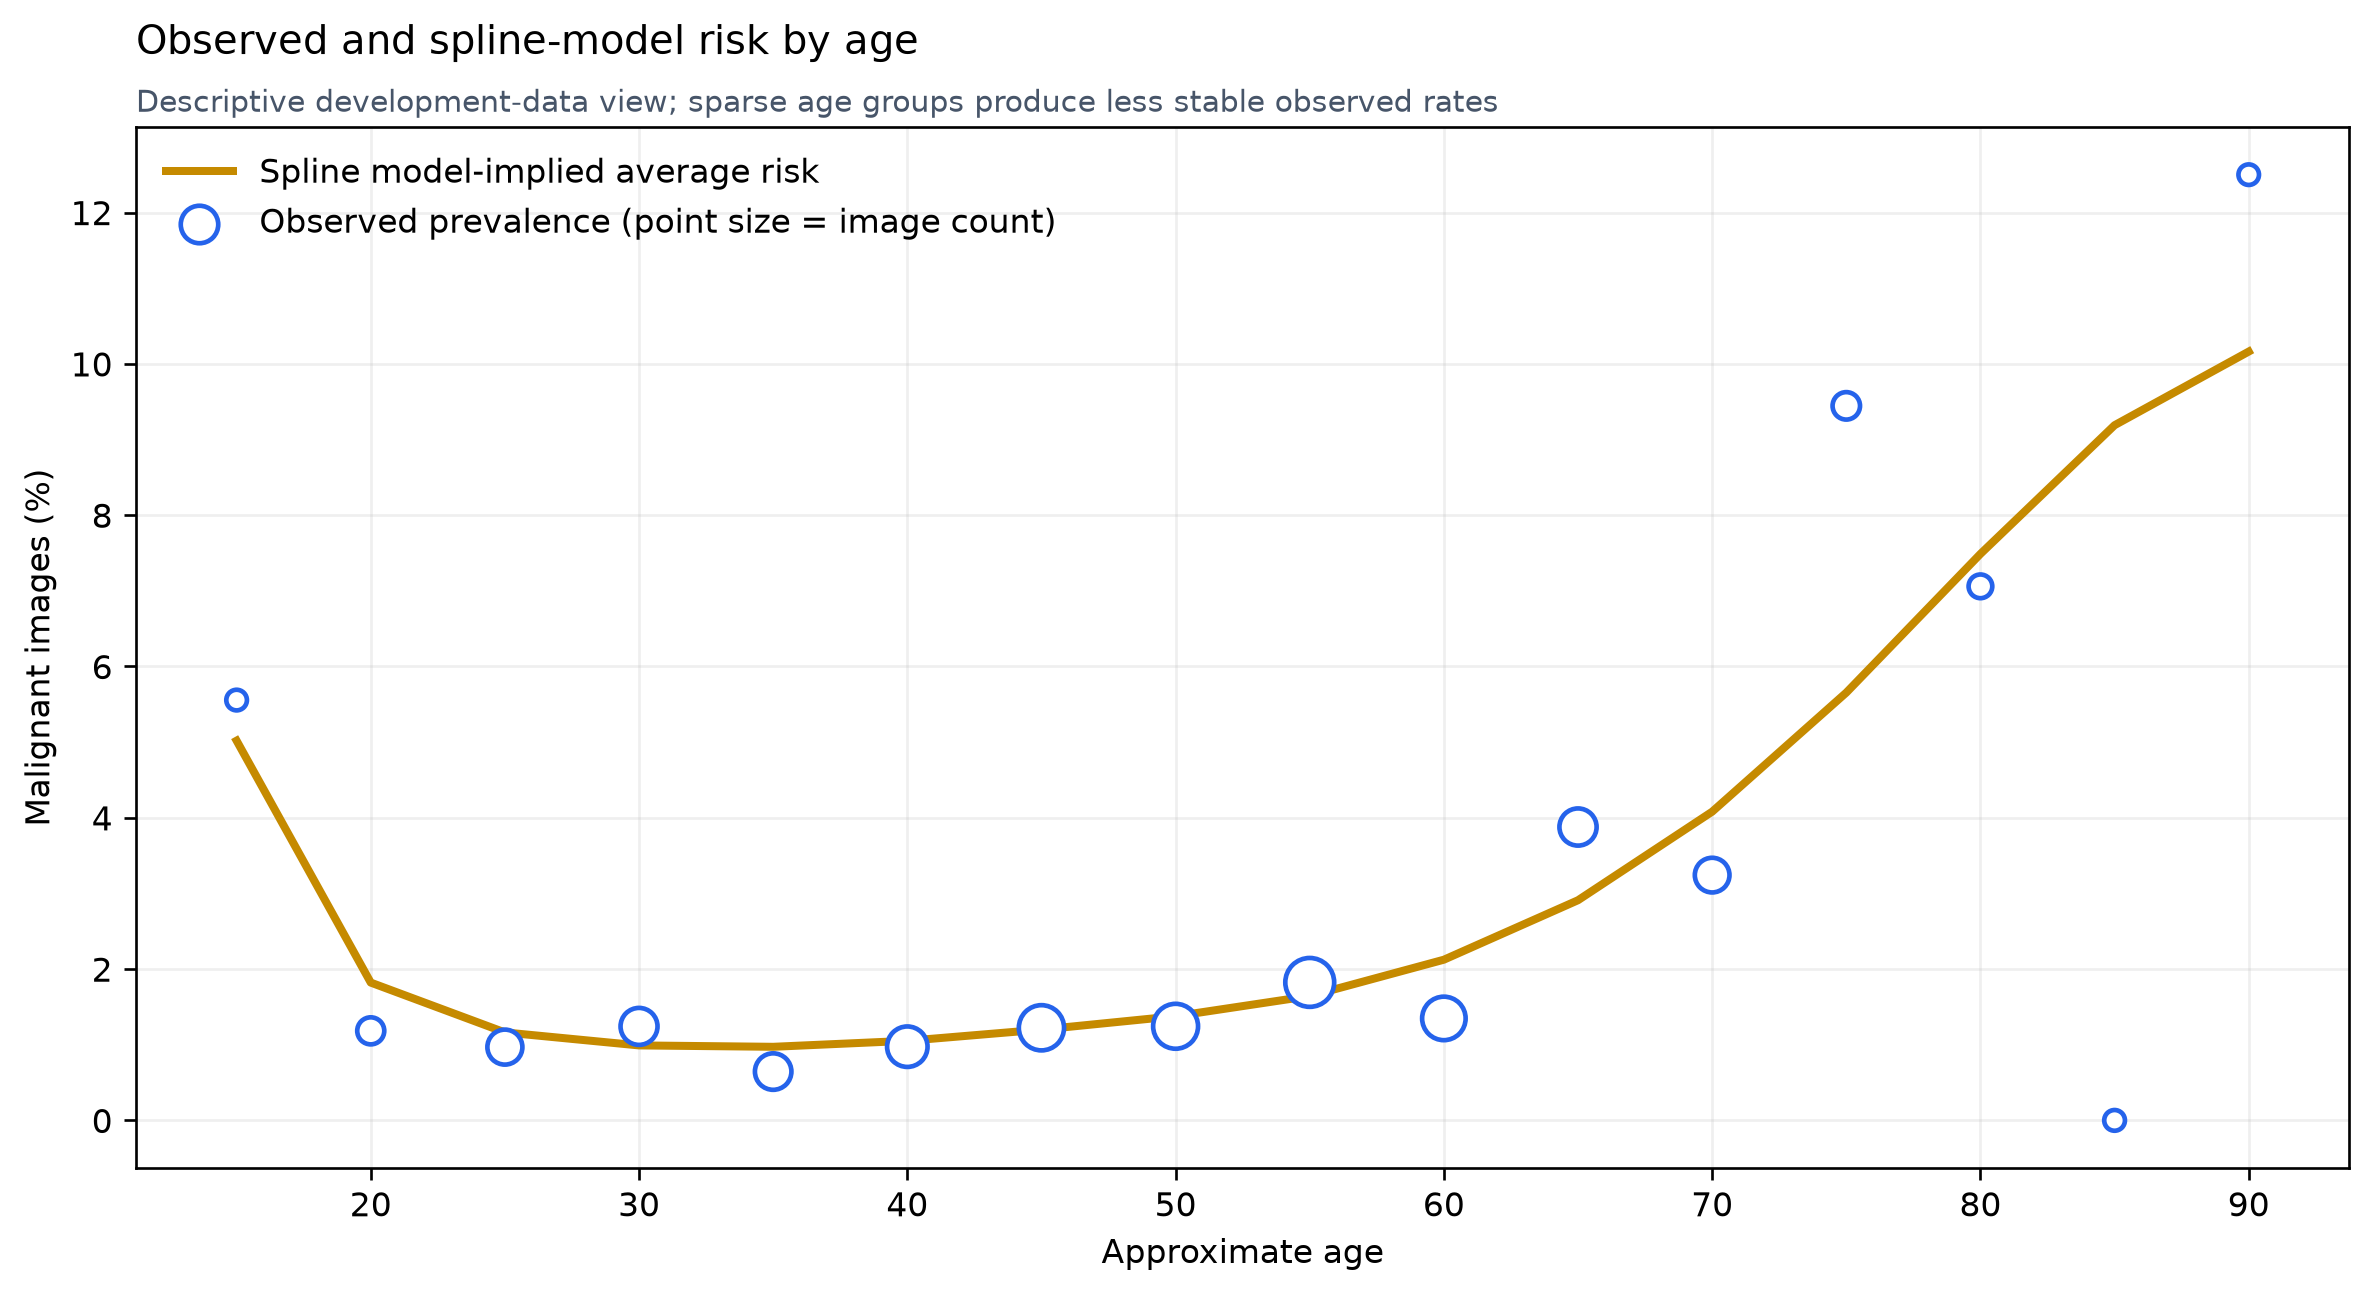

,age,images,malignant_images,Observed prevalence (%),Model-implied average risk (%)
0,15,18,1,5.56,5.02
1,20,169,2,1.18,1.82
2,25,413,4,0.97,1.16
3,30,483,6,1.24,0.99
4,35,465,3,0.65,0.97
5,40,616,6,0.97,1.05
6,45,817,10,1.22,1.20
7,50,804,10,1.24,1.38
8,55,987,18,1.82,1.64
9,60,742,10,1.35,2.12


In [10]:
marginal_age_risk = marginal_age_profile(train, meta)
observed_age_risk =  (
    train.assign(age=pd.to_numeric(train["age_approx"], errors="coerce"))
    .groupby("age", as_index=False)["target"]
    .agg(images="size", malignant_images="sum", observed_prevalence="mean")
)
age_interpretation = observed_age_risk.merge(marginal_age_risk, on="age", how="left")

fig, axis = plt.subplots(figsize=(10, 5.5))
axis.plot(
    age_interpretation["age"],
    age_interpretation["model_implied_average_risk"] * 100,
    color="#C58A00",
    linewidth=2.4,
    label="Spline model-implied average risk",
)
marker_sizes = 35 + 180 * age_interpretation["images"] / age_interpretation["images"].max()
axis.scatter(
    age_interpretation["age"],
    age_interpretation["observed_prevalence"] * 100,
    s=marker_sizes,
    facecolors="white",
    edgecolors="#2563EB",
    linewidths=1.4,
    label="Observed prevalence (point size = image count)",
    zorder=3,
)
axis.set_xlabel("Approximate age")
axis.set_ylabel("Malignant images (%)")
axis.set_title("Observed and spline-model risk by age", loc="left", pad=22)
axis.text(
    0,
    1.015,
    "Descriptive development-data view; sparse age groups produce less stable observed rates",
    transform=axis.transAxes,
    fontsize=9,
    color="#475569",
)
axis.grid(alpha=0.20)
axis.legend(frameon=False)
fig.tight_layout()
finish_figure(fig, 'metadata_observed_and_marginal_age')

display(
    age_interpretation.assign(
        **{
            "Observed prevalence (%)": age_interpretation["observed_prevalence"] * 100,
            "Model-implied average risk (%)": age_interpretation["model_implied_average_risk"] * 100,
        }
    )[
        ["age", "images", "malignant_images", "Observed prevalence (%)", "Model-implied average risk (%)"]
    ].round(2)
)

The fitted curve generally rises at older ages. The observed rates fluctuate, particularly where few images are available: age 90 has only 16 retained images, for example. The curve smooths those jumps, but fitting a smooth line does not remove uncertainty. This is an association in the development data, not evidence that age causes an individual lesion to be malignant.


### 7. Describe the observed rates by sex and site

The next table counts malignant images within each category. Read the image count and malignant count beside the percentage. A high percentage based on a handful of cases provides much weaker evidence than the same percentage based on many cases.


In [11]:
def prevalence_by_category(frame, column, feature_label):
    summary = (
        frame.groupby(column, dropna=False)["target"]
        .agg(images="size", malignant_images="sum", prevalence="mean")
        .reset_index()
        .rename(columns={column: "Category"})
    )
    summary.insert(0, "Feature", feature_label)
    summary["Prevalence (%)"] = summary.pop("prevalence") * 100
    return summary.sort_values("Prevalence (%)", ascending=False)


category_prevalence = pd.concat(
    [
        prevalence_by_category(train, "sex", "Sex"),
        prevalence_by_category(
            train,
            "anatom_site_general_challenge",
            "Anatomical site",
        ),
    ],
    ignore_index=True,
)
category_prevalence.round({"Prevalence (%)": 2})
display(category_prevalence.round(2))


,Feature,Category,images,malignant_images,Prevalence (%)
0,Sex,male,3229,74,2.29
1,Sex,female,3477,53,1.52
2,Anatomical site,oral/genital,33,3,9.09
3,Anatomical site,head/neck,393,21,5.34
4,Anatomical site,upper extremity,1044,22,2.11
5,Anatomical site,torso,3351,54,1.61
6,Anatomical site,lower extremity,1620,25,1.54
7,Anatomical site,Unknown,195,2,1.03
8,Anatomical site,palms/soles,70,0,0.00


These are unadjusted descriptive rates. Categories with few images or malignant cases, such as oral/genital and palms/soles, can show extreme percentages by chance and should not be ranked as if their estimates were equally reliable.


### 8. Choose exploratory cutoffs for confusion matrices

A cutoff turns a probability into a decision: images at or above it are flagged. At 0.50, every model in this run leaves every image unflagged. The probabilities are mostly small because malignant images are rare.

For each learned model, we try every distinct predicted probability, plus 0 and 1. At each candidate cutoff, we calculate recall and specificity, the fraction of benign images left unflagged. We choose the cutoff with the largest balanced accuracy, the average of recall and specificity. If candidates tie, we choose the one closest to 0.50. The dummy stays at 0.50 because it has no useful ranking within a fold.

The same OOF labels choose the cutoffs and assess their decisions, so this is an exploratory illustration. The training-only selection in notebook 08 provides a better check of a complete cutoff procedure.


In [12]:

def select_balanced_accuracy_threshold(y_true, probabilities):
    cutoff = exploratory_cutoff(y_true, probabilities)
    return cutoff, float(balanced_accuracy_score(y_true, np.asarray(probabilities) >= cutoff))
y_true = oof_predictions["target"].to_numpy()
selected_thresholds = {"dummy": 0.50}
threshold_rows = []
default_threshold_rows = []

for model_name in estimators:
    probabilities = oof_predictions[f"{model_name}_probability"].to_numpy()

    default_tn, default_fp, default_fn, default_tp = confusion_matrix(
        y_true,
        probabilities >= 0.50,
        labels=[0, 1],
    ).ravel()
    default_threshold_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Threshold": 0.50,
            "TN": default_tn,
            "FP": default_fp,
            "FN": default_fn,
            "TP": default_tp,
        }
    )

    if model_name == "dummy":
        threshold = 0.50
        balanced_accuracy = balanced_accuracy_score(y_true, probabilities >= threshold)
        threshold_type = "Fixed"
    else:
        threshold, balanced_accuracy = select_balanced_accuracy_threshold(
            y_true,
            probabilities,
        )
        selected_thresholds[model_name] = threshold
        threshold_type = "Maximum balanced accuracy"

    threshold_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Threshold": threshold,
            "Threshold type": threshold_type,
            "Balanced accuracy": balanced_accuracy,
        }
    )

print("Default 0.50 threshold results:")
display(pd.DataFrame(default_threshold_rows).set_index("Model"))

threshold_summary = pd.DataFrame(threshold_rows).set_index("Model")
threshold_summary.round({"Threshold": 4, "Balanced accuracy": 4})

Default 0.50 threshold results:


,Threshold,TN,FP,FN,TP
Model,,,,,
Prevalence dummy,0.5,6579,0,127,0
Standard logistic regression,0.5,6579,0,127,0
Spline logistic regression,0.5,6579,0,127,0
Random forest,0.5,6579,0,127,0
XGBoost,0.5,6579,0,127,0


,Threshold,Threshold type,Balanced accuracy
Model,,,
Prevalence dummy,0.5000,Fixed,0.5000
Standard logistic regression,0.0272,Maximum balanced accuracy,0.6119
Spline logistic regression,0.0227,Maximum balanced accuracy,0.6431
Random forest,0.0285,Maximum balanced accuracy,0.6051
XGBoost,0.0199,Maximum balanced accuracy,0.5978


### 9. Read the confusion matrices

Each panel shows the counts produced by its model's chosen cutoff. Rows are the actual class and columns are the predicted class. The upper-left cell is a benign image left unflagged (TN); the upper-right is a benign image flagged by mistake (FP). The lower-left is a missed malignant image (FN); the lower-right is a malignant image found (TP).

The percentages use the actual class as their denominator. The top row adds to 100% of benign images and the bottom row adds to 100% of malignant images. Compare the bottom-right percentage with the top-right percentage to see the detection/false-alarm trade-off. Darker blue means more images, using one shared count scale across panels. Read the numbers as well as the shading, because benign images greatly outnumber malignant ones.

These matrices make the practical cost of a cutoff visible. They do not show final-test performance or establish a clinical decision rule.


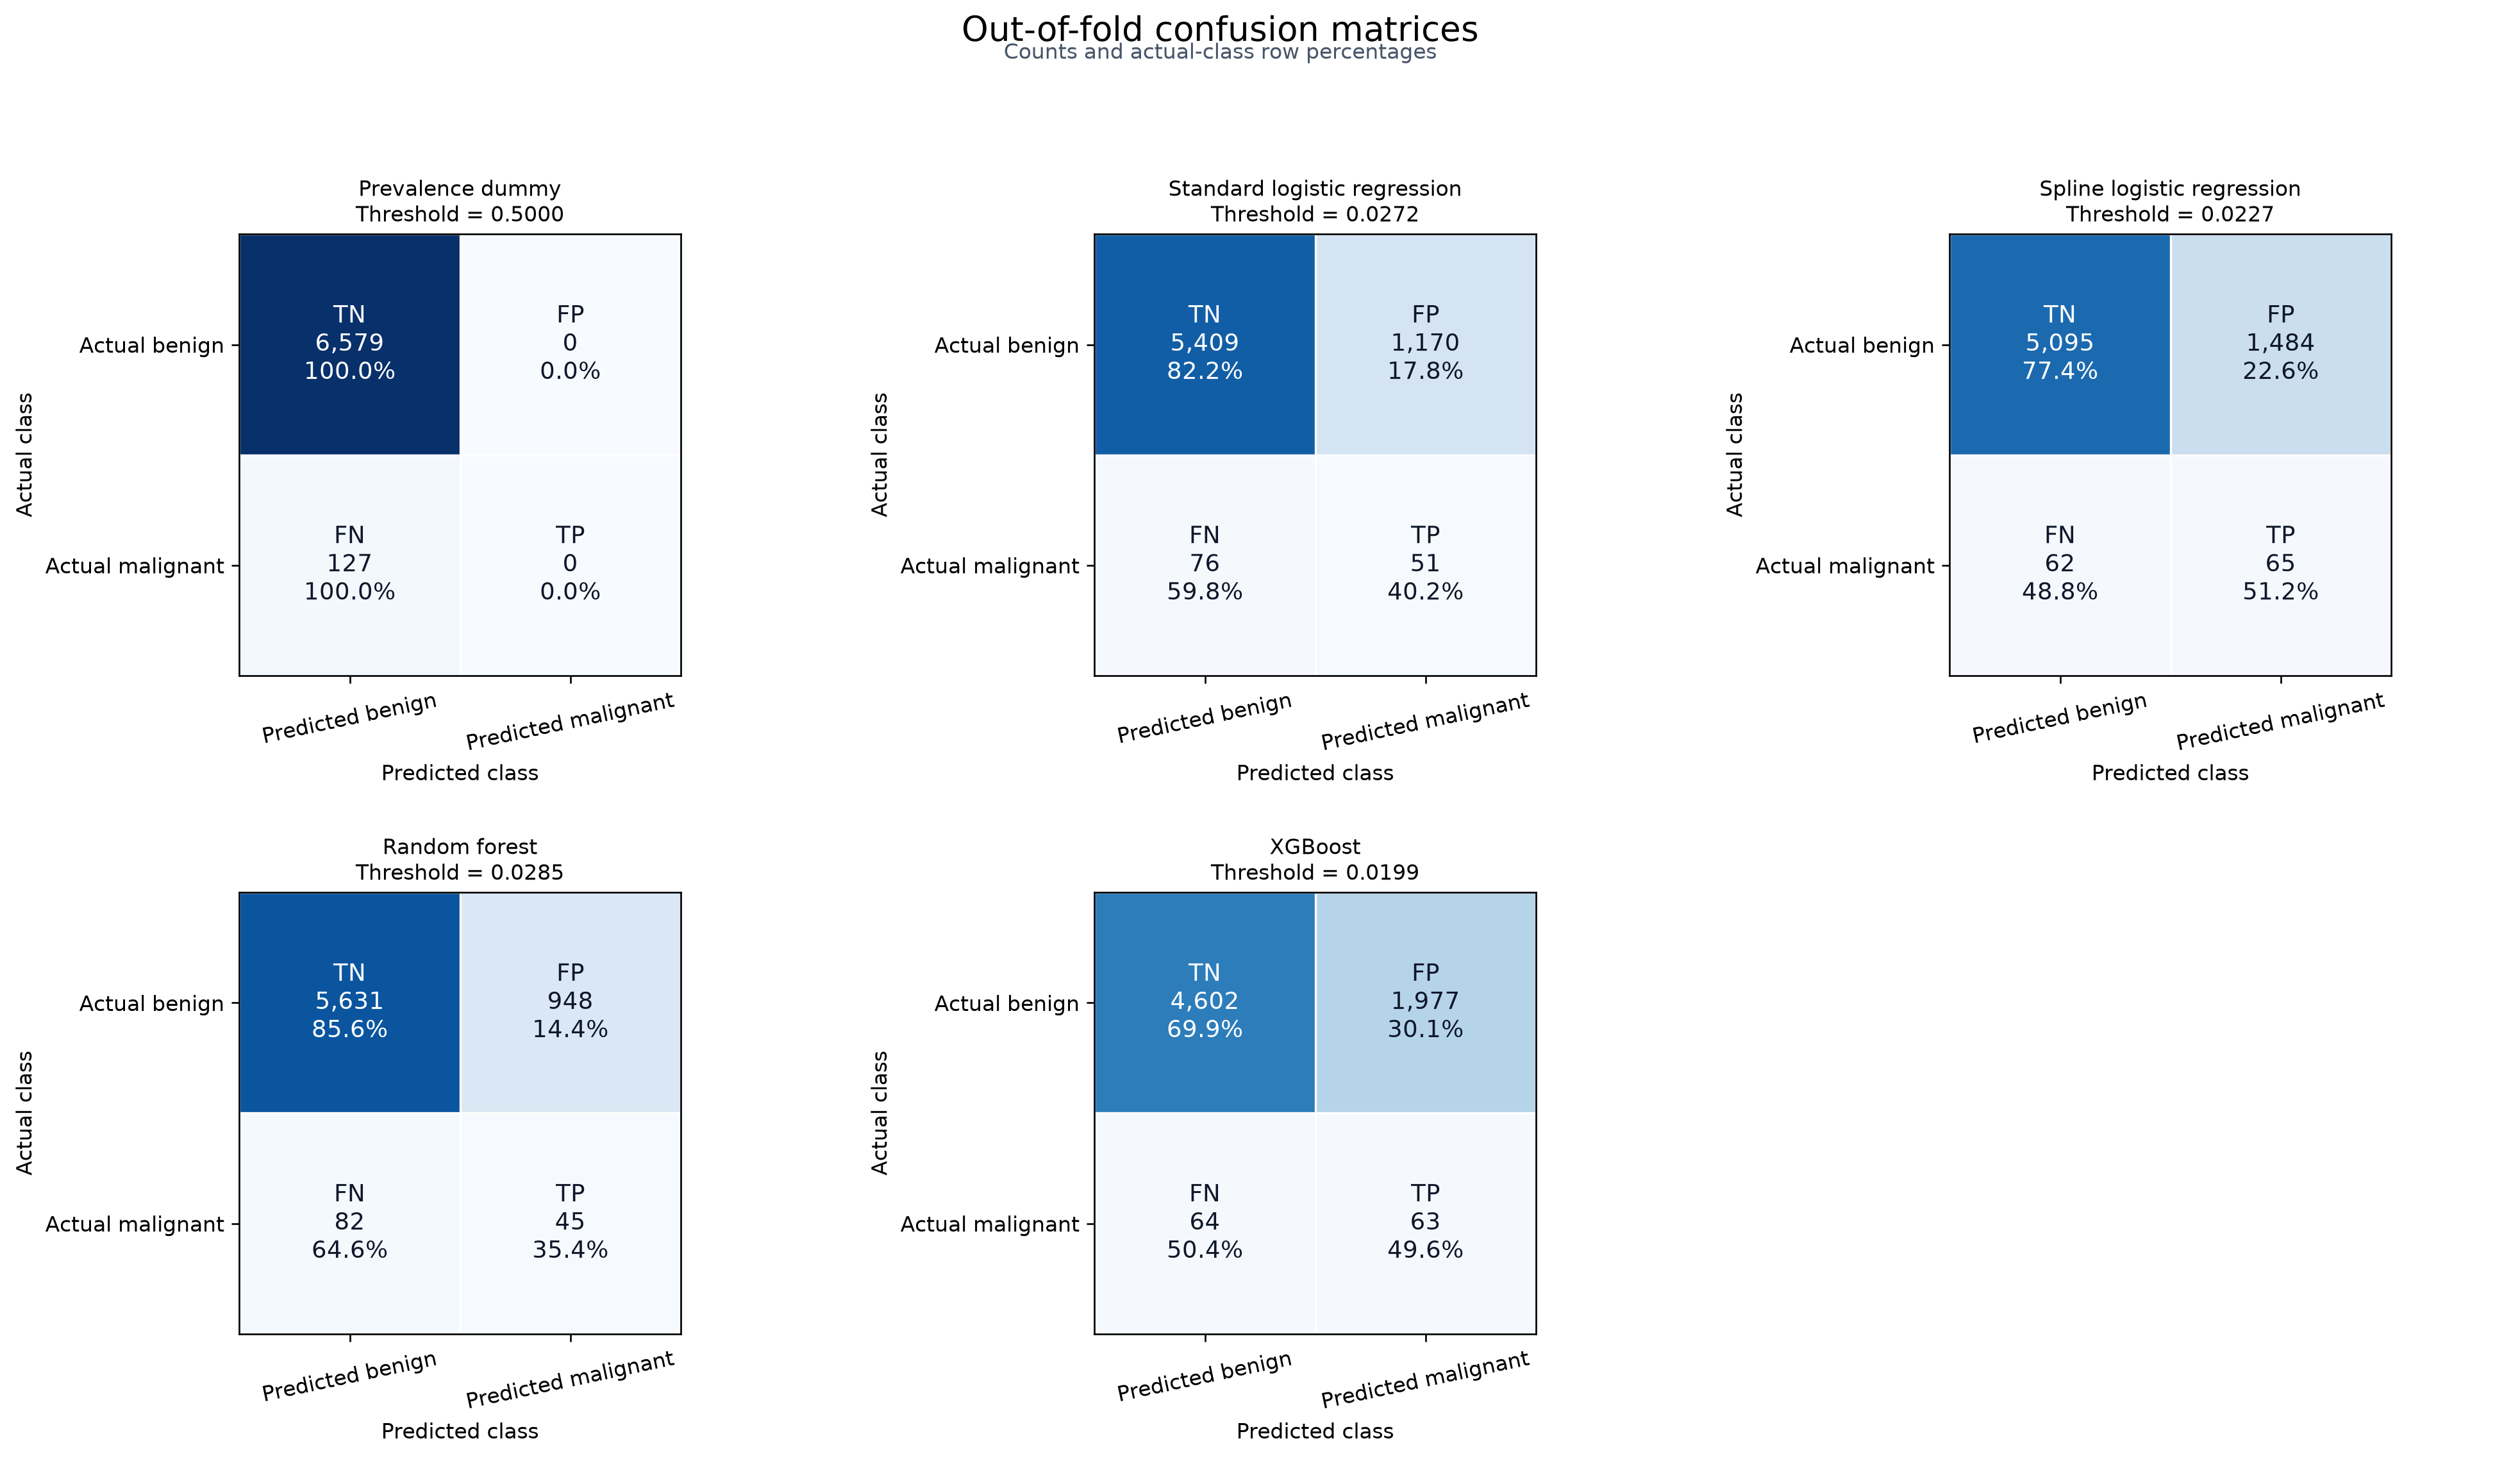

,Threshold,TN,TN % of actual benign,FP,FP % of actual benign,FN,FN % of actual malignant,TP,TP % of actual malignant,Precision among predicted malignant (%)
Model,,,,,,,,,,
Prevalence dummy,0.5000,6579,100.0000,0,0.0000,127,100.0000,0,0.0000,0.0000
Standard logistic regression,0.0272,5409,82.2161,1170,17.7839,76,59.8425,51,40.1575,4.1769
Spline logistic regression,0.0227,5095,77.4434,1484,22.5566,62,48.8189,65,51.1811,4.1963
Random forest,0.0285,5631,85.5905,948,14.4095,82,64.5669,45,35.4331,4.5317
XGBoost,0.0199,4602,69.9498,1977,30.0502,64,50.3937,63,49.6063,3.0882


In [13]:
confusion_matrices = {}
for model_name in estimators:
    probabilities = oof_predictions[f"{model_name}_probability"].to_numpy()
    predicted_labels = (probabilities >= selected_thresholds[model_name]).astype(int)
    confusion_matrices[model_name] = confusion_matrix(
        y_true,
        predicted_labels,
        labels=[0, 1],
    )

shared_maximum = max(matrix.max() for matrix in confusion_matrices.values())
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
confusion_rows = []

for axis, model_name in zip(axes.flat, estimators):
    threshold = selected_thresholds[model_name]
    matrix = confusion_matrices[model_name]
    tn, fp, fn, tp = matrix.ravel()
    row_percentages = matrix / matrix.sum(axis=1, keepdims=True) * 100

    annotations = np.array(
        [
            [
                f"TN\n{tn:,}\n{row_percentages[0, 0]:.1f}%",
                f"FP\n{fp:,}\n{row_percentages[0, 1]:.1f}%",
            ],
            [
                f"FN\n{fn:,}\n{row_percentages[1, 0]:.1f}%",
                f"TP\n{tp:,}\n{row_percentages[1, 1]:.1f}%",
            ],
        ]
    )

    axis.imshow(matrix, cmap="Blues", vmin=0, vmax=shared_maximum)
    for row in range(2):
        for column in range(2):
            text_color = "white" if matrix[row, column] > shared_maximum / 2 else "#0F172A"
            axis.text(
                column,
                row,
                annotations[row, column],
                ha="center",
                va="center",
                color=text_color,
                fontsize=11,
            )

    axis.set_xticks([0, 1], labels=["Predicted benign", "Predicted malignant"])
    axis.set_yticks([0, 1], labels=["Actual benign", "Actual malignant"])
    axis.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    axis.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    axis.grid(which="minor", color="white", linestyle="-", linewidth=1)
    axis.tick_params(which="minor", bottom=False, left=False)
    axis.set_title(
        f"{MODEL_LABELS[model_name]}\nThreshold = {threshold:.4f}",
        fontsize=10,
    )
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Actual class")
    axis.tick_params(axis="x", rotation=12)

    confusion_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Threshold": threshold,
            "TN": tn,
            "TN % of actual benign": row_percentages[0, 0],
            "FP": fp,
            "FP % of actual benign": row_percentages[0, 1],
            "FN": fn,
            "FN % of actual malignant": row_percentages[1, 0],
            "TP": tp,
            "TP % of actual malignant": row_percentages[1, 1],
            "Precision among predicted malignant (%)": (
                tp / (tp + fp) * 100 if (tp + fp) else 0.0
            ),
        }
    )

for unused_axis in axes.flat[len(estimators):]:
    unused_axis.axis("off")

fig.suptitle("Out-of-fold confusion matrices", fontsize=16, y=0.995)
fig.text(
    0.5,
    0.965,
    "Counts and actual-class row percentages",
    ha="center",
    fontsize=10,
    color="#475569",
)
fig.tight_layout(rect=[0, 0, 1, 0.94], h_pad=2.2, w_pad=1.8)
finish_figure(fig, 'metadata_exploratory_confusions')

confusion_results = pd.DataFrame(confusion_rows).set_index("Model")
confusion_results.round(
    {
        "Threshold": 4,
        "TN % of actual benign": 1,
        "FP % of actual benign": 1,
        "FN % of actual malignant": 1,
        "TP % of actual malignant": 1,
        "Precision among predicted malignant (%)": 1,
    }
)
display(confusion_results.round(4))


## Where this comparison leads

[04_metadata_baselines.ipynb](04_metadata_baselines.ipynb) gives a shorter walkthrough of the two basic references. [06_metadata_neural_network.ipynb](06_metadata_neural_network.ipynb) checks whether a small neural network helps, and [07_metadata_tuning.ipynb](07_metadata_tuning.ipynb) checks changes to the model settings.

[08_metadata_robustness.ipynb](08_metadata_robustness.ipynb) then adds patient-based uncertainty intervals, training-only cutoff selection, calibration plots and subgroup checks. The [methodology guide](../../docs/metadata_methodology.md) explains why those steps matter.


## Limitations

These folds have been used to compare several models and field combinations. Choosing the most promising result after seeing all of them can make that winner look better than it will on new patients. Patient separation prevents direct training leakage, but it cannot remove the effect of repeated development choices.

There are only 127 malignant images from 88 patients, and some ages and sites contain very few cases. This notebook does not provide confidence intervals for the model or field comparisons. Its age plot and category rates are descriptive associations; they cannot explain causation. The cutoffs are chosen and assessed on the same predictions, and the plots do not establish calibrated probabilities or clinical safety.

Metadata contains no lesion appearance. These results do not establish performance at another hospital or on the reserved test set, which has not been used to evaluate these models.


## Summary

The spline logistic model is the strongest of these five fixed methods on pooled AP (0.0492) and ROC-AUC (0.6428). Age supplies most of the individual metadata signal, and site adds information. Sex adds only a small change beyond those fields.

Its primary mean-fold AP is 0.0648, ahead of XGBoost (0.0591), categorical logistic (0.0567) and forest (0.0548). Retain the fixed spline as the primary metadata model and the dummy as the reference. Keep the standard logistic and tree results as comparisons. At the spline's exploratory cutoff of 0.0227, it finds 65 of 127 malignant images (51.2%) while incorrectly flagging 1,484 of 6,579 benign images (22.6%). That trade-off shows why a higher ranking score alone is insufficient.

Next, check the network and tuning experiments, then use notebook 08 to assess uncertainty, probability calibration and a cutoff selected from training patients. Freeze the complete method before evaluating the reserved test set once.


## Additional deduplicated-workflow diagnostics

The complete original section sequence above is retained as the template. The following clearly labelled additions document clean artifact verification, training support and explanatory diagnostics that were not figures in the original. They remain secondary development evidence and do not select another model or cutoff.

In [14]:

import json
from melanoma_detection.metadata_evaluation import decision_metrics
from melanoma_detection.dedup_notebook_metadata import (
    LABELS, COLORS, saved_metadata, metric_table, curve_figure, metric_bar_figure,
    cutoff_table, confusion_figure, estimator_diagnostics, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
display(pd.DataFrame([{"Dataset identity": bundle["identity"]["dataset_identity"],
    "New CPU fits": meta["receipt"]["executed_fits"], "Reused clean fits": meta["receipt"]["reused_fits"],
    "Images with matching predictions": len(frame), "Reserved test loaded": False}]))


,Dataset identity,New CPU fits,Reused clean fits,Images with matching predictions,Reserved test loaded
0,0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae...,695,60,6706,False


In [15]:
coefficients, importances, age_profiles = estimator_diagnostics(meta)

### Added diagnostic: 7. Inspect tree importances with the proper cautions

Sum encoded-column importances back to age, sex and site. Forest values use impurity-based importance; XGBoost uses its saved normalised tree importance. Many age categories can receive more opportunities for splits. These measures are associations within fitted trees and cannot establish out-of-sample field importance or causation; compare fields within a model, not magnitudes across algorithms.

,model,feature,mean,std
0,random_forest,age_approx,0.5374,0.0269
1,random_forest,anatom_site_general_challenge,0.3419,0.0296
2,random_forest,sex,0.1207,0.0115
3,xgboost,age_approx,0.7323,0.0190
4,xgboost,anatom_site_general_challenge,0.2393,0.0132
5,xgboost,sex,0.0284,0.0094


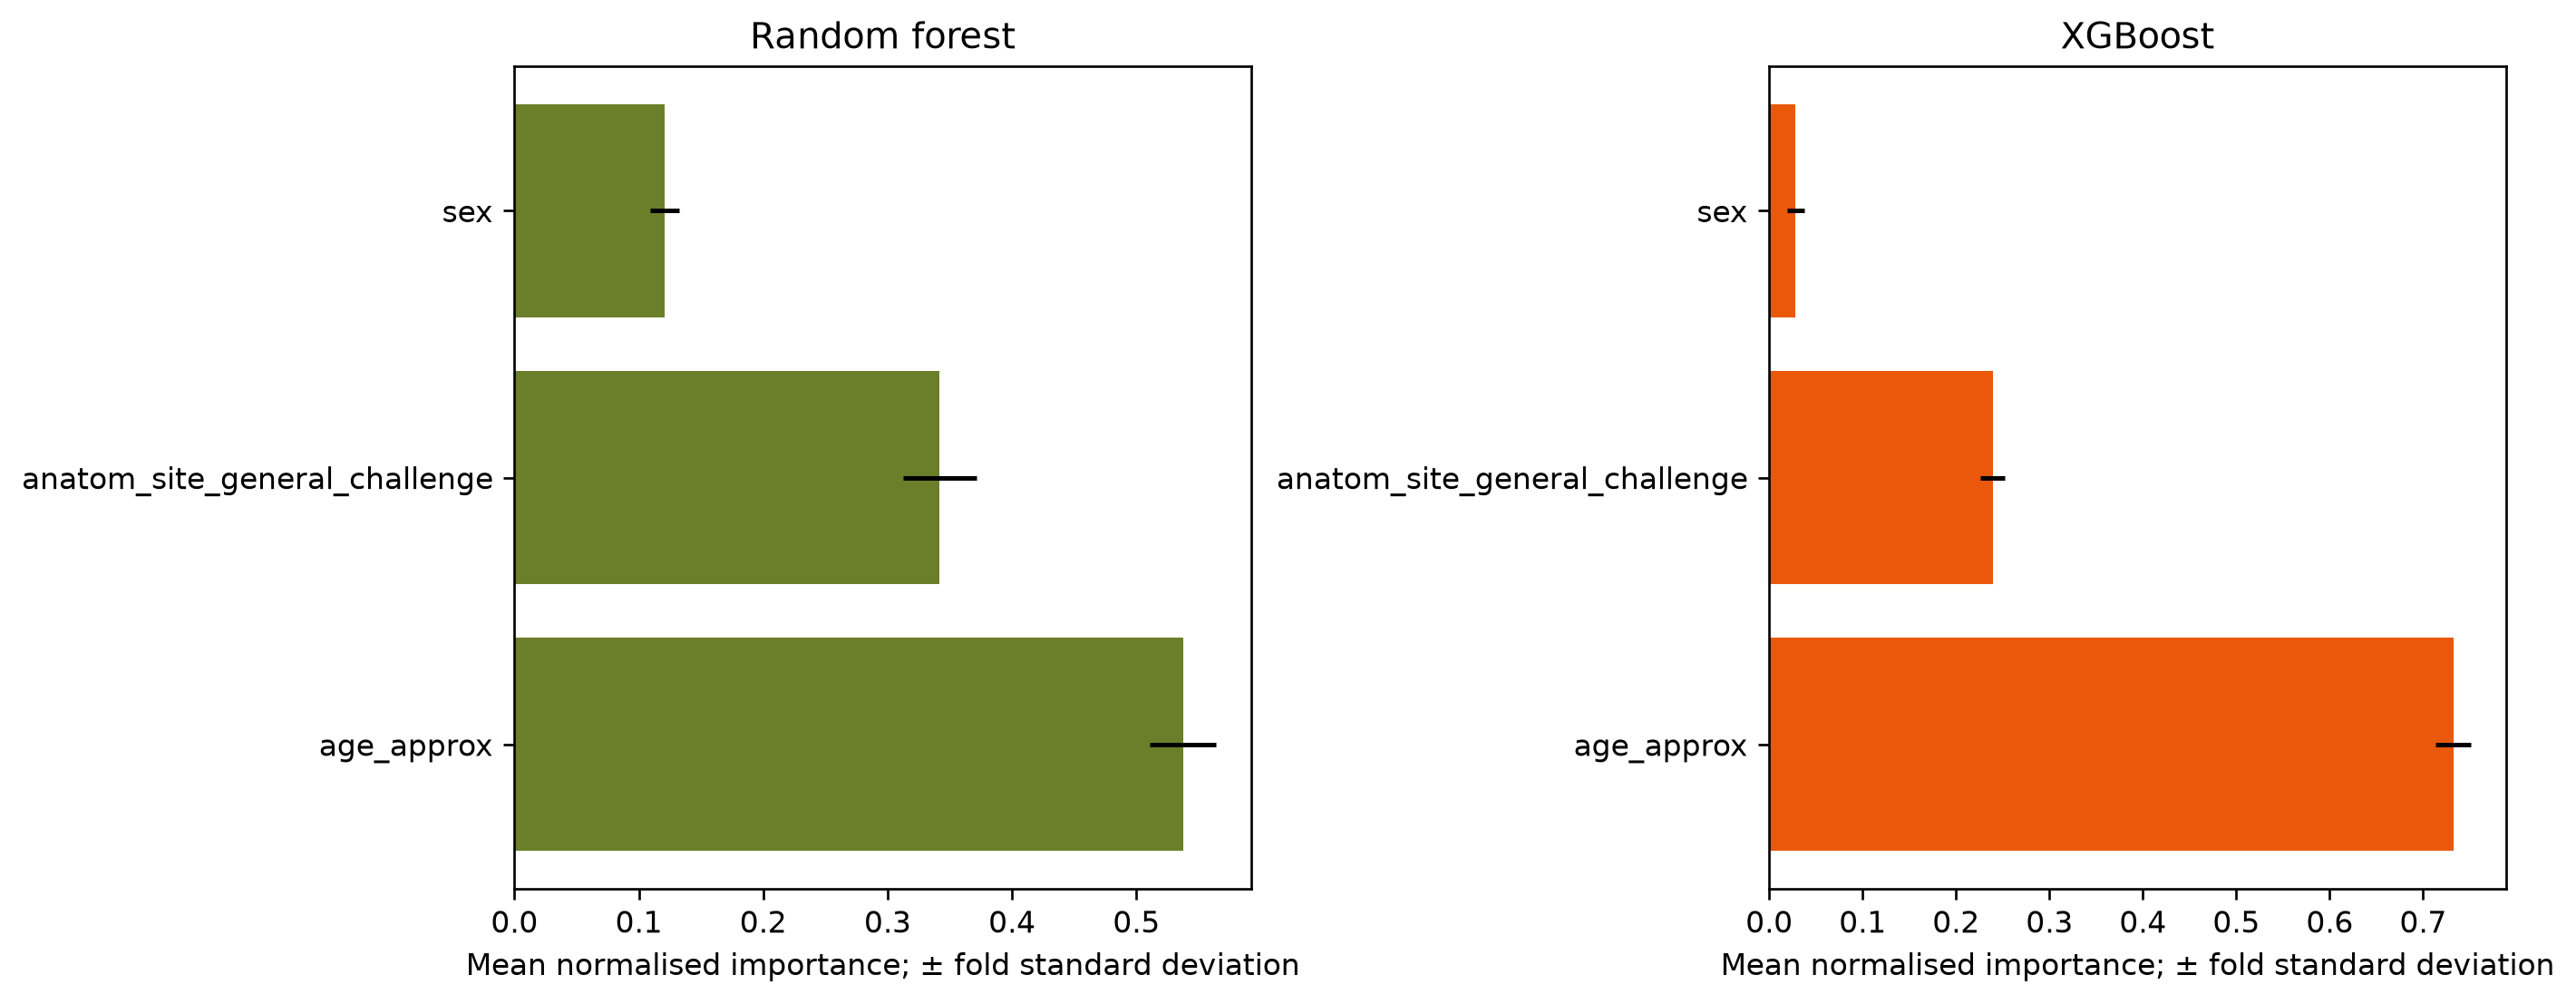

In [16]:
summary = importances.groupby(["model", "feature"]).importance.agg(["mean", "std"]).reset_index()
display(summary.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), layout="constrained")
for ax, model in zip(axes, ["random_forest", "xgboost"]):
    rows = summary.loc[summary.model.eq(model)]
    ax.barh(rows.feature, rows["mean"], xerr=rows["std"], color={"random_forest": "#6B7F2A", "xgboost": "#EA580C"}[model])
    ax.set(xlabel="Mean normalised importance; ± fold standard deviation", title=LABELS[model])
finish_figure(fig, "metadata_saved_tree_importances")